# CNN Model

In [1]:
import os, shutil, pathlib
import matplotlib.pyplot as plt
import keras
from keras import layers
from keras.utils import image_dataset_from_directory
import tensorflow as tf
import numpy as np

from PIL import Image
import time

base_dir = pathlib.Path("./datasets/dinnerware_mix_background")

C:\Users\riikk\anaconda3\envs\keras\Lib\site-packages\requests\__init__.py:92: RequestsDependencyWarning: Unable to find acceptable character detection dependency (chardet or charset_normalizer).
  warnings.warn(


## Data Preprossing

In [2]:
keras.utils.set_random_seed(2)

categories = ["bowl", "glass", "mug", "plate"]
splits = ["train", "validation", "test"]
image_extensions = ('.jpg', '.jpeg')

def count_dataset_images():
    for split in splits:
        print(f"\nsplit: {split}")
        total = 0

        for category in categories:
            folder = os.path.join("./datasets/data_sorted", split, category)

            image_count = sum(
                1 for filename in os.listdir(folder)
                if filename.lower().endswith(image_extensions)
            )

            total += image_count

            print(f"  {category}: {image_count} images")

        print(f"  Total: {total} images")


count_dataset_images()


split: train
  bowl: 56 images
  glass: 59 images
  mug: 62 images
  plate: 55 images
  Total: 232 images

split: validation
  bowl: 11 images
  glass: 13 images
  mug: 14 images
  plate: 11 images
  Total: 49 images

split: test
  bowl: 13 images
  glass: 14 images
  mug: 14 images
  plate: 12 images
  Total: 53 images


In [3]:
train_dataset = image_dataset_from_directory(
    base_dir / "train",
    image_size = (224, 224),
    batch_size = 32,
    seed=123,
)
validation_dataset = image_dataset_from_directory(
    base_dir / "validation",
    image_size = (224, 224),
    batch_size = 32,
    seed=123,
)
test_dataset = image_dataset_from_directory(
    base_dir / "test",
    image_size = (224, 224),
    batch_size = 32,
    seed=123,
)

Found 232 files belonging to 4 classes.
Found 49 files belonging to 4 classes.
Found 53 files belonging to 4 classes.


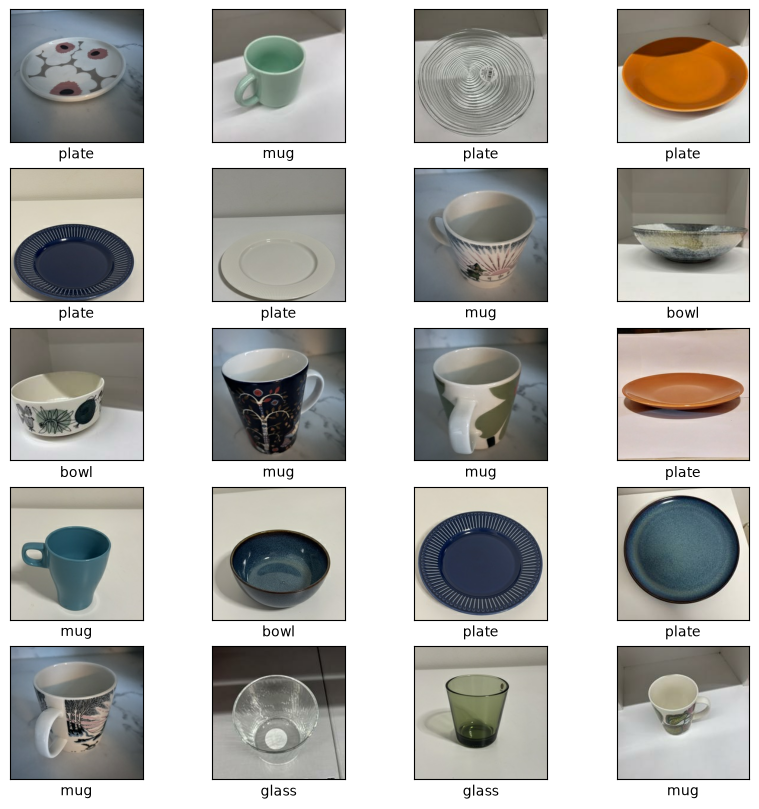

In [4]:
import matplotlib.pyplot as plt

# Haetaan yksi batch kuvista ja labeleista
plt.figure(figsize=(10, 10))

class_names = train_dataset.class_names

for images, labels in train_dataset.take(1):
    for i in range(20):
        plt.subplot(5, 4, i + 1)
        plt.xticks([])
        plt.yticks([])
        plt.grid(False)

        plt.imshow(images[i].numpy().astype("uint8"))
        plt.xlabel(class_names[labels[i]])

plt.show()

In [5]:
"""
from keras import Sequential
from keras import layers

data_augmentation = Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.2),
])

inputs = keras.Input(shape=(224, 224, 3))
x = data_augmentation(inputs)
x = layers.Rescaling(1.0/255)(x)
x = layers.Conv2D(filters=32, kernel_size=3, activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Conv2D(filters=64, kernel_size=3, activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Conv2D(filters=128, kernel_size=3, activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Conv2D(filters=256, kernel_size=3, activation="relu")(x)
x = layers.Flatten()(x)
x = layers.Dropout(0.5)(x)
outputs = layers.Dense(4, activation='softmax') (x)
model = keras.Model(inputs=inputs, outputs=outputs)


model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

model.summary()
"""

'\nfrom keras import Sequential\nfrom keras import layers\n\ndata_augmentation = Sequential([\n    layers.RandomFlip("horizontal"),\n    layers.RandomRotation(0.1),\n    layers.RandomZoom(0.2),\n])\n\ninputs = keras.Input(shape=(224, 224, 3))\nx = data_augmentation(inputs)\nx = layers.Rescaling(1.0/255)(x)\nx = layers.Conv2D(filters=32, kernel_size=3, activation="relu")(x)\nx = layers.MaxPooling2D(pool_size=2)(x)\nx = layers.Conv2D(filters=64, kernel_size=3, activation="relu")(x)\nx = layers.MaxPooling2D(pool_size=2)(x)\nx = layers.Conv2D(filters=128, kernel_size=3, activation="relu")(x)\nx = layers.MaxPooling2D(pool_size=2)(x)\nx = layers.Conv2D(filters=256, kernel_size=3, activation="relu")(x)\nx = layers.Flatten()(x)\nx = layers.Dropout(0.5)(x)\noutputs = layers.Dense(4, activation=\'softmax\') (x)\nmodel = keras.Model(inputs=inputs, outputs=outputs)\n\n\nmodel.compile(optimizer=\'adam\', loss=\'sparse_categorical_crossentropy\', metrics=[\'accuracy\'])\n\nmodel.summary()\n'

## Modelling

In [6]:
data_augmentation = keras.Sequential(
    [
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.2),
        layers.RandomZoom(0.2),
        layers.RandomContrast(0.2)
    ]
)

In [28]:
img = train_dataset[:1].astype("float32")

plt.figure(figsize=(8, 8))
for i in range(9):
    aug = data_augmentation(img, training=True)
    plt.subplot(3, 3, i + 1)
    plt.imshow(keras.ops.convert_to_numpy(aug[0]).astype("uint8"))
    plt.axis("off")
plt.show()



TypeError: '_PrefetchDataset' object is not subscriptable

In [7]:
model = keras.Sequential([
    keras.Input(shape=(224, 224, 3)),
    data_augmentation,
    layers.Rescaling(1.0/255),
    
    layers.Conv2D(32, kernel_size=3, activation="relu"),
    layers.Conv2D(32, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),
    
    layers.Conv2D(64, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),
    
    layers.Conv2D(128, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),   

    layers.Conv2D(256, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),   
    
    layers.Flatten(),
    layers.Dropout(0.10),
    layers.Dense(len(class_names), activation="softmax"),
])
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 220, 220, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 110, 110, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 108, 108, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 24, 24, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 12, 12, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 36864)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 36864)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │       147,460 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 545,124 (2.08 MB)

 Trainable params: 545,124 (2.08 MB)

 Non-trainable params: 0 (0.00 B)

In [8]:
for data_batch, labels_batch in train_dataset:
    print("data batch shape:", data_batch.shape)
    print("labels batch shape:", labels_batch.shape)
    break

data batch shape: (32, 224, 224, 3)
labels batch shape: (32,)


## Compile and train the model

In [9]:
model.compile(
    loss=keras.losses.SparseCategoricalCrossentropy(),
    optimizer=keras.optimizers.Adam(),
    metrics=["accuracy"],
)

In [10]:
callbacks = [
    keras.callbacks.ModelCheckpoint(
        filepath="convnet_from_scratch_with_augmentation.keras",
        save_best_only=True,
        monitor="val_loss"),
    keras.callbacks.EarlyStopping(
        monitor="val_loss", 
        patience=7, 
        restore_best_weights=True)
]


In [11]:
callback = keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)

t0 = time.time()

history = model.fit(train_dataset, epochs=70, batch_size=64, validation_data=validation_dataset, callbacks=callbacks)

train_time = time.time() - t0
print(f"Training time: {train_time:.1f} s")

/opt/anaconda3/envs/keras/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


Epoch 1/70
8/8 ━━━━━━━━━━━━━━━━━━━━ 6s 618ms/step - accuracy: 0.2284 - loss: 1.3994 - val_accuracy: 0.2245 - val_loss: 1.3873
Epoch 2/70
8/8 ━━━━━━━━━━━━━━━━━━━━ 5s 583ms/step - accuracy: 0.2888 - loss: 1.3740 - val_accuracy: 0.3061 - val_loss: 1.3799
Epoch 3/70
8/8 ━━━━━━━━━━━━━━━━━━━━ 5s 573ms/step - accuracy: 0.3534 - loss: 1.2977 - val_accuracy: 0.4490 - val_loss: 1.2811
Epoch 4/70
8/8 ━━━━━━━━━━━━━━━━━━━━ 5s 570ms/step - accuracy: 0.4181 - loss: 1.2350 - val_accuracy: 0.4082 - val_loss: 1.2855
Epoch 5/70
8/8 ━━━━━━━━━━━━━━━━━━━━ 5s 584ms/step - accuracy: 0.4052 - loss: 1.2619 - val_accuracy: 0.4694 - val_loss: 1.2116
Epoch 6/70
8/8 ━━━━━━━━━━━━━━━━━━━━ 5s 575ms/step - accuracy: 0.4138 - loss: 1.2559 - val_accuracy: 0.4694 - val_loss: 1.1863
Epoch 7/70
8/8 ━━━━━━━━━━━━━━━━━━━━ 5s 570ms/step - accuracy: 0.4181 - loss: 1.2387 - val_accuracy: 0.4082 - val_loss: 1.2104
Epoch 8/70
8/8 ━━━━━━━━━━━━━━━━━━━━ 5s 574ms/step - accuracy: 0.4267 - loss: 1.2213 - val_accuracy: 0.3265 - val_loss:

## Learning Curves

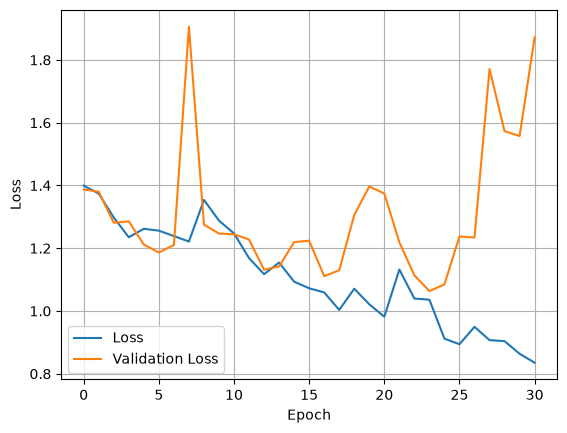

In [12]:
plt.plot(history.history["loss"], label="Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.legend()
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.grid()
plt.show()

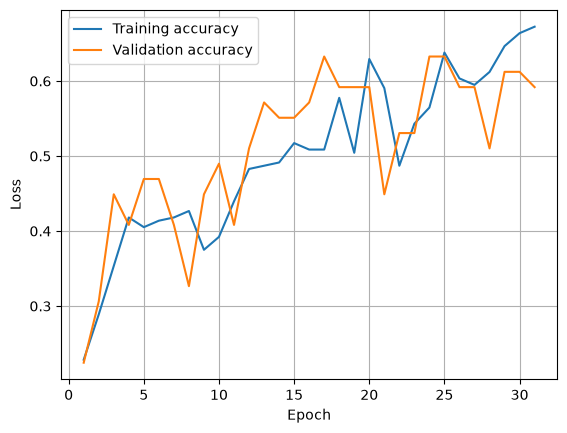

In [18]:
loss = history.history["loss"]
val_loss = history.history["val_loss"]

plt.plot(epochs, accuracy, label="Training accuracy")
plt.plot(epochs, val_accuracy, label="Validation accuracy")
plt.legend()
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.grid()
plt.show()

## Test perfomance

In [17]:
test_model = keras.models.load_model("convnet_from_scratch_with_augmentation.keras")
test_loss, test_acc = test_model.evaluate(test_dataset)

print(f"Test accuracy: {test_acc:.3f}")
print(f"Test loss: {test_loss:.3f}")

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 112ms/step - accuracy: 0.4906 - loss: 1.3387
Test accuracy: 0.491
Test loss: 1.339


In [15]:
#train_full = train_dataset.concatenate(validation_dataset)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 200ms/step


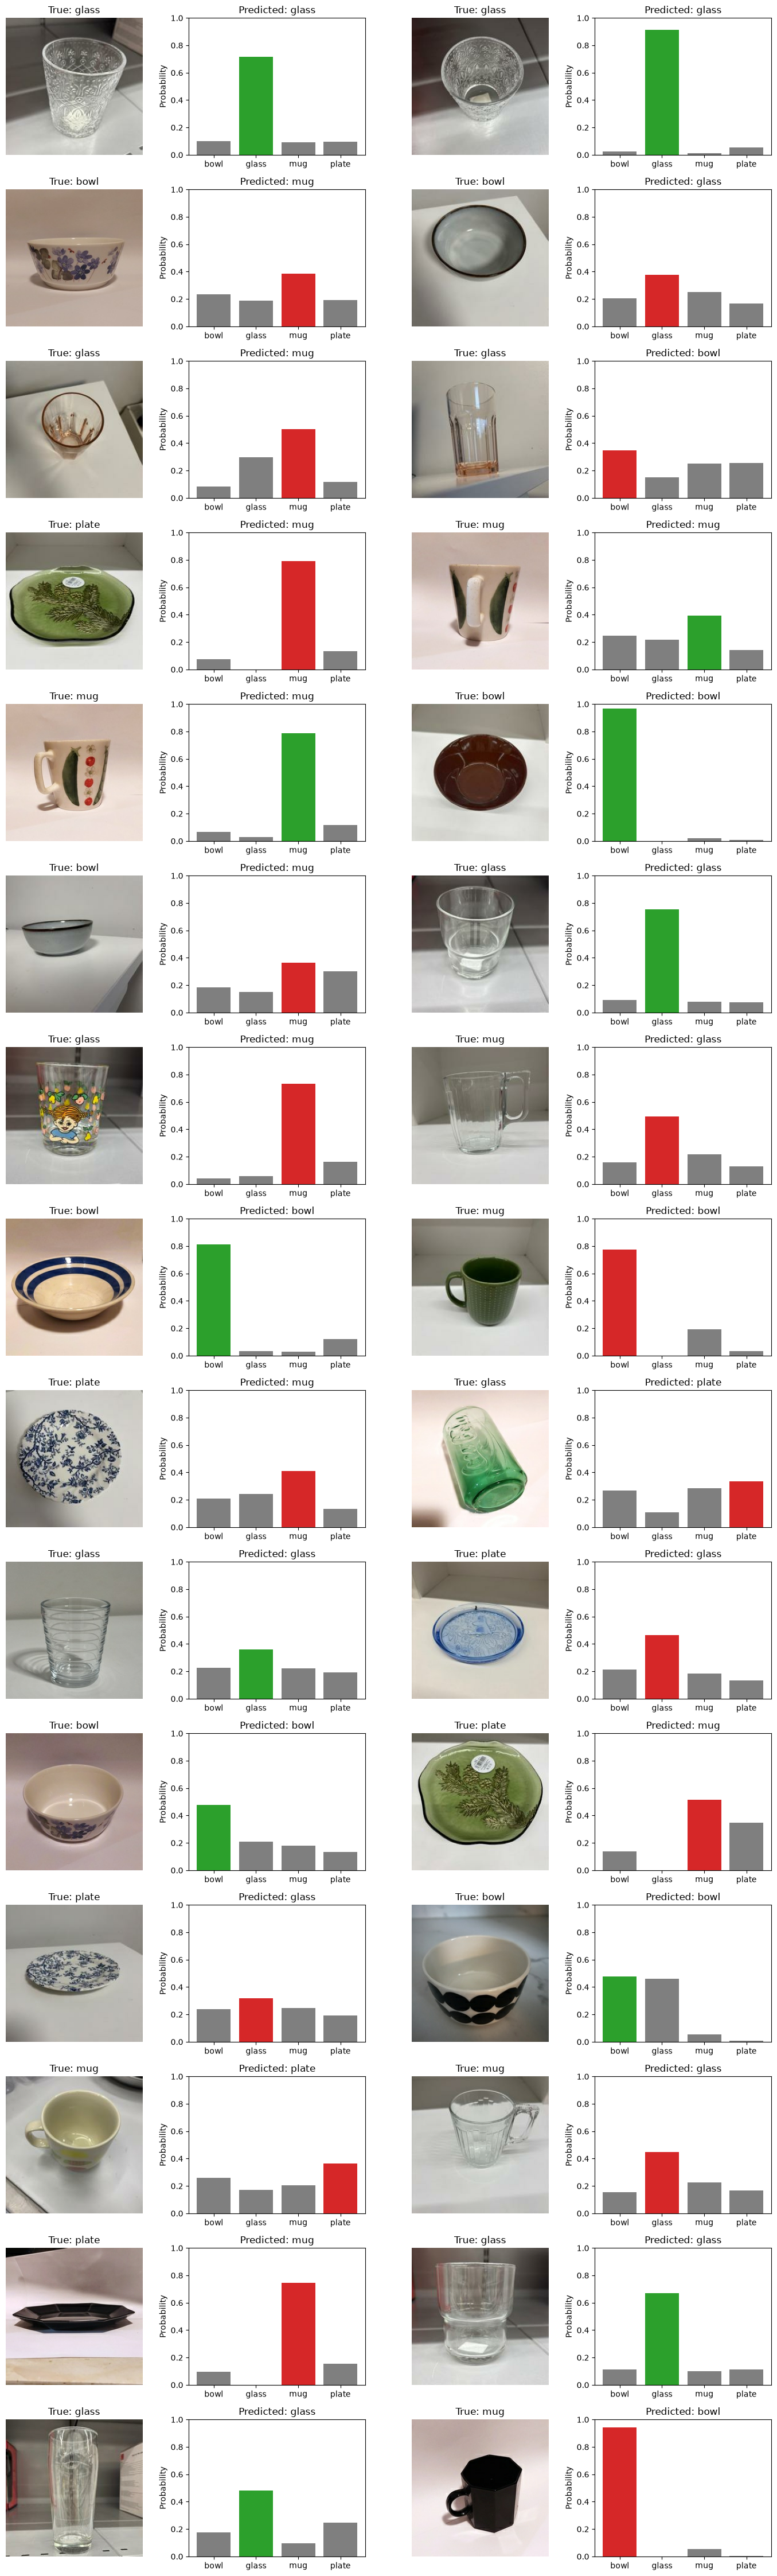

In [16]:
x, y = next(iter(test_dataset)) 
probs = test_model.predict(x)

start = 0
images_n = 30
rows = images_n // 2

plt.figure(figsize=(14, 3 * rows))

for k in range(images_n):
    i = start + k
    true_label = int(y[i])
    pred_label = int(np.argmax(probs[i]))
    correct = true_label == pred_label

    plt.subplot(rows, 4, 2 * k + 1)
    plt.imshow(x[i].numpy().astype("uint8"))
    plt.axis("off")
    plt.title(f"True: {class_names[true_label]}")

    plt.subplot(rows, 4, 2 * k + 2)
    colors = ["tab:gray"] * len(class_names)
    colors[pred_label] = "tab:green" if correct else "tab:red"
    plt.bar(class_names, probs[i], color=colors)
    plt.ylim(0, 1)
    plt.ylabel("Probability")
    plt.title(f"Predicted: {class_names[pred_label]}")

plt.tight_layout()
plt.show()

/var/folders/q9/3lq265vn6s5gcmgb5vd5lk5h0000gn/T/ipykernel_53300/3390622527.py:5: RuntimeWarning: Mean of empty slice
  mean_probs = [probs[true_label == c].mean(axis=0) for c in range(4)]
/opt/anaconda3/envs/keras/lib/python3.12/site-packages/numpy/_core/_methods.py:134: RuntimeWarning: invalid value encountered in divide
  ret = um.true_divide(


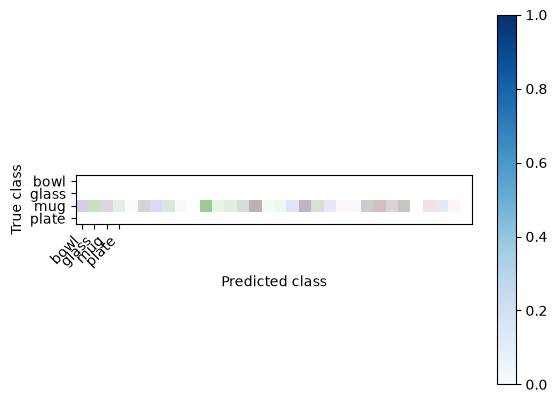

In [24]:
x, y = next(iter(test_dataset))
probs = model.predict(x, verbose=0)
#y_true = y.flatten()

mean_probs = [probs[true_label == c].mean(axis=0) for c in range(4)]

plt.imshow(mean_probs, cmap="Blues", vmin=0, vmax=1)
plt.colorbar()
plt.xticks(range(4), class_names, rotation=45, ha="right")
plt.yticks(range(4), class_names)
plt.xlabel("Predicted class")
plt.ylabel("True class")
plt.show()

In [29]:
## Kirjoitetaan uuden notebookiin

## Dataset description Riikka

## Mallien suorituskyvyn vertailun: Nur

## Kohtaamasi haasteet ja ratkaisut Anni
- Kuvien ottaaminen, taustan päättääminen, esim: värikas tai musta-valkoinen, asento
- Kuvien esikäsittely: rajaus, koon muuttaminen.
- Kuvien laittaminen repoon
- Datan jakaminen: eri hakemistoihin harjoitus-, validointi- ja testidatalle,
- Datan jaon vaikeus: manuaalinen ja automaattinen skriptilla.
- Ylioppimiseen vähentäminen, hyvää tarkkuus, ja loss
- Finetuned mallin ajaamiseen hiitaus: piti miettiä huolellaa mitä muokkaa, ennen kuin ajaa malli.

## Pohdinnan eri mallien soveltuvuudesta ongelmaan Sandra
- CNN malli ei soveltuu koviin hyvin, kun meillä on vähän dataa.
- Feature_Extraction_VGG16 malli antaa parrempia tuloksia, on paljon nopeampi verrattuna CNN malli, mutta tulos ei ollut 100% prosenttin tarkkudella, loss... 
- Fine_tuned malli on erittäin hidas verrattuna muu 2 malli...

## Teköälyn käyttö Anni
- kuvien esitkäsittely skripti
- kuvien alustava jakoon ennen kuin manuaalisesti jaoteltu
- Debuggaus
- Plottaukseen